In [13]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import poisson, gamma as gamma_dist
import arviz as az

c:\Users\aweso\anaconda3\envs\TensorFlowBase\lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
#SIR Model System of ODEs
def sir_model(S, I, R, beta, gamma, N):
    #dS/dt
    dS = -beta * S * I / N

    #dI/dt
    dI =  beta * S * I / N - gamma * I

    #dR/dt
    dR =  gamma * I
    return dS, dI, dR

#Implememntation of Rugne-Kutta 4th order method to solve the SIR model ODEs
def simulate_sir_rk4(beta, gamma, N=5000, S0=4990, I0=10, T=60, h=1.0):
    steps = int(T / h)

    #Initial conditions 
    S, I, R = S0, I0, N - S0 - I0

    #Storing the trajectories
    S_list = [S]
    I_list = [I]
    R_list = [R]

    for _ in range(steps):
        # k1
        dS1, dI1, dR1 = sir_model(S, I, R, beta, gamma, N)

        # k2
        dS2, dI2, dR2 = sir_model(
            S + 0.5*h*dS1,
            I + 0.5*h*dI1,
            R + 0.5*h*dR1,
            beta, gamma, N
        )

        # k3
        dS3, dI3, dR3 = sir_model(
            S + 0.5*h*dS2,
            I + 0.5*h*dI2,
            R + 0.5*h*dR2,
            beta, gamma, N
        )

        # k4
        dS4, dI4, dR4 = sir_model(
            S + h*dS3,
            I + h*dI3,
            R + h*dR3,
            beta, gamma, N
        )

        # Update
        S += (h/6)*(dS1 + 2*dS2 + 2*dS3 + dS4)
        I += (h/6)*(dI1 + 2*dI2 + 2*dI3 + dI4)
        R += (h/6)*(dR1 + 2*dR2 + 2*dR3 + dR4)

        S_list.append(S)
        I_list.append(I)
        R_list.append(R)

    # Daily new infections
    I_curve = np.array(I_list)
    delta_I = np.maximum(np.diff(I_curve), 1e-6)

    return delta_I

# Log-posterior function for beta and gamma given observed data x_obs
def log_posterior(beta, gamma, x_obs, alpha_b=2, b_b=10,
                  alpha_g=2, b_g=10):
    if beta <= 0 or gamma <= 0:
        return -np.inf
    delta_I = simulate_sir_rk4(beta, gamma)
    log_lik = np.sum(poisson.logpmf(x_obs, delta_I))
    log_prior = ((alpha_b - 1)*np.log(beta) - b_b*beta
               + (alpha_g - 1)*np.log(gamma) - b_g*gamma)
    return log_lik + log_prior

# Metropolis-within-Gibbs sampler 
def gibbs_sampler(x_obs, n_iter=7000, burnin=2000,
                  sigma_beta=0.005, sigma_gamma=0.009):

    # Sample initial beta and gamma from prior
    beta_curr  = gamma_dist.rvs(a=.2, scale=1/10)  
    gamma_curr = gamma_dist.rvs(a=.2, scale=1/10) 

    samples_beta  = []
    samples_gamma = []

    gamma_acc = 0
    beta_acc = 0

    for k in range(n_iter):

        # Update beta
        beta_prop = beta_curr + np.random.normal(0, sigma_beta) #Metropolis proposal
        log_r = log_posterior(beta_prop, gamma_curr, x_obs) \
              - log_posterior(beta_curr, gamma_curr, x_obs)
        if np.log(np.random.uniform()) < log_r: #Accept proposal
            beta_acc += 1
            beta_curr = beta_prop

        # Update gamma
        gamma_prop = gamma_curr + np.random.normal(0, sigma_gamma) #Metropolis proposal
        log_r = log_posterior(beta_curr, gamma_prop, x_obs) \
              - log_posterior(beta_curr, gamma_curr, x_obs)
        if np.log(np.random.uniform()) < log_r: #Accept proposal
            gamma_acc += 1
            gamma_curr = gamma_prop

        if k >= burnin: #Burning the intial samples for CLT to hold
            samples_beta.append(beta_curr)
            samples_gamma.append(gamma_curr)

    print(f"Acceptance rate for beta: {beta_acc/n_iter:.2f}")
    print(f"Acceptance rate for gamma: {gamma_acc/n_iter:.2f}")

    return np.array(samples_beta), np.array(samples_gamma)

# Generating synthetic data
def generate_synthetic_data(beta_true=.3, gamma_true=.1, T=60):
    delta_I = simulate_sir_rk4(beta_true, gamma_true, T=T)
    x_obs = poisson.rvs(delta_I)
    return x_obs

In [3]:
x_obs = generate_synthetic_data()

In [4]:
samples_beta, samples_gamma = gibbs_sampler(x_obs)

Acceptance rate for beta: 0.16
Acceptance rate for gamma: 0.14


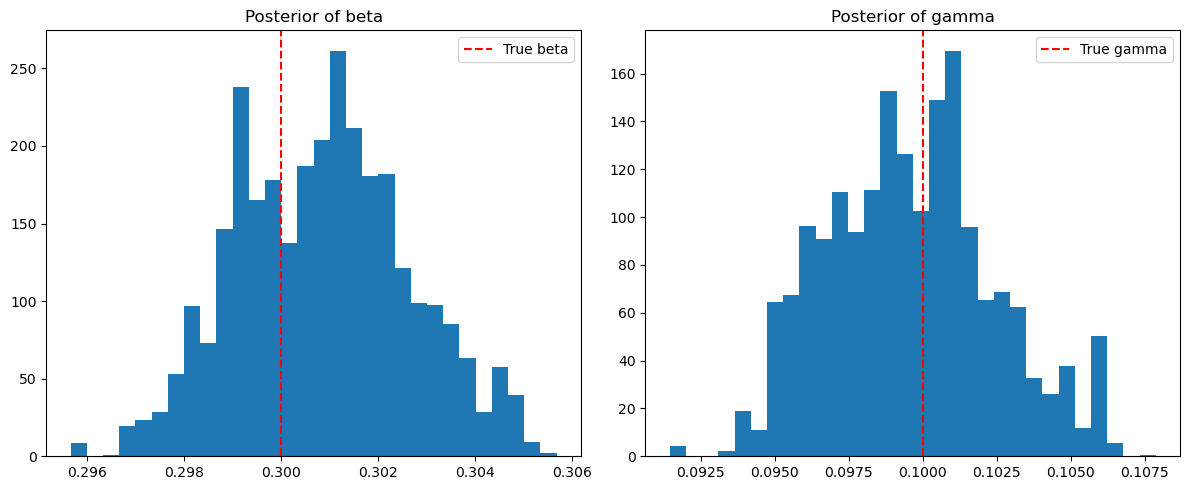

In [5]:
# --- Plotting ---
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.hist(samples_beta, bins=30, density=True)
plt.axvline(.3, color='red', linestyle='--', label='True beta')
plt.title('Posterior of beta')
plt.legend()
plt.subplot(1,2,2)
plt.hist(samples_gamma, bins=30, density=True)
plt.axvline(.1, color='red', linestyle='--', label='True gamma')
plt.title('Posterior of gamma')
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
beta_mean = np.mean(samples_beta)
gamma_mean = np.mean(samples_gamma)

beta_var = np.var(samples_beta)
gamma_var = np.var(samples_gamma)

print(f"Estimated beta: {beta_mean:.4f} (var: {beta_var:.6f})")
print(f"Estimated gamma: {gamma_mean:.4f} (var: {gamma_var:.6f})")

Estimated beta: 0.3009 (var: 0.000003)
Estimated gamma: 0.0996 (var: 0.000008)


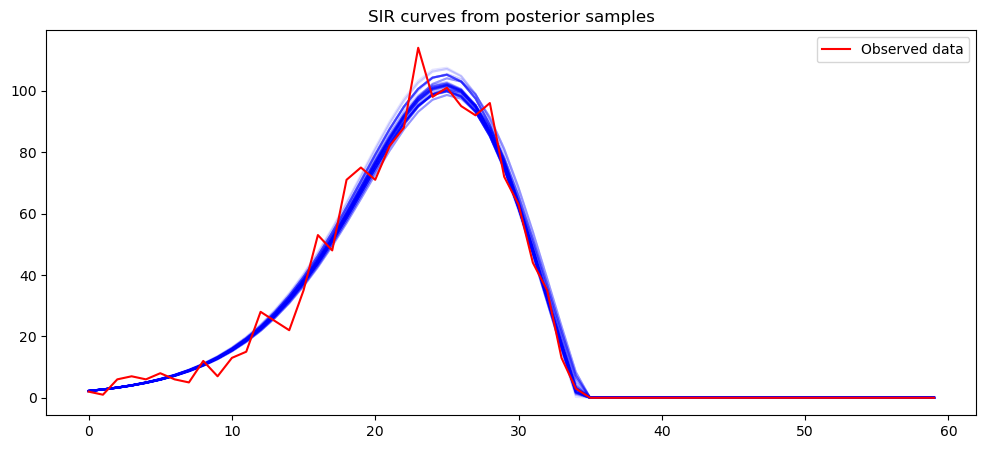

In [7]:
#plotting SIR curves with posterior samples
plt.figure(figsize=(12,5))
for i in range(100):
    beta_sample = samples_beta[i]
    gamma_sample = samples_gamma[i]
    delta_I_sample = simulate_sir_rk4(beta_sample, gamma_sample)
    plt.plot(delta_I_sample, color='blue', alpha=0.1)
plt.plot(x_obs, color='red', label='Observed data')
plt.title('SIR curves from posterior samples')
plt.legend()
plt.show()


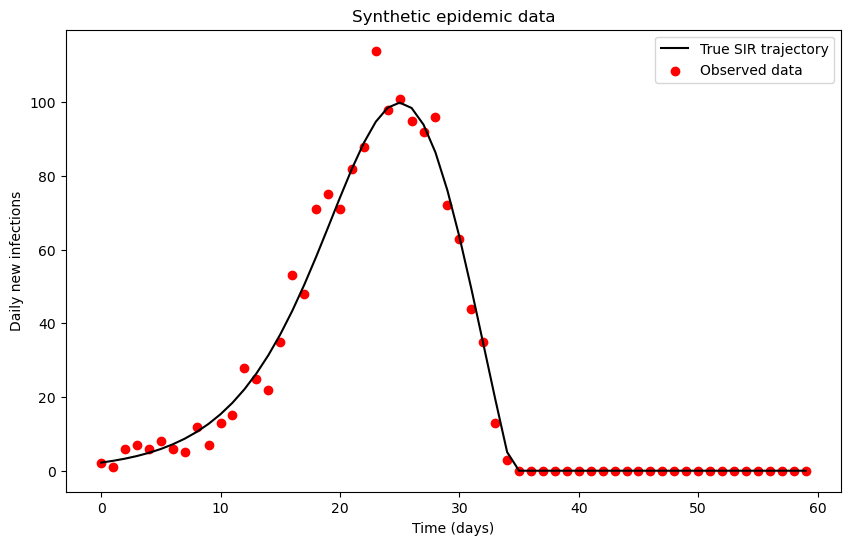

In [8]:
#Synthetic epidemic data. The solid line shows the true SIR model trajectory for β∗ = 0.3, γ∗ = 0.1, and the points show the noisy observed daily incidence counts.
plt.figure (figsize=(10,6))
delta_I_true = simulate_sir_rk4(0.3, 0.1)
plt.plot(delta_I_true, color='black', label='True SIR trajectory')
plt.scatter(range(len(x_obs)), x_obs, color='red', label='Observed data')
plt.title('Synthetic epidemic data')
plt.xlabel('Time (days)')
plt.ylabel('Daily new infections')
plt.legend()
plt.show()

In [9]:
#Calculating Error Metrics and Accuracy
beta_true = 0.3
gamma_true = 0.1

#Absolute Error
abs_err_beta = abs(beta_mean - beta_true)
abs_err_gamma = abs(gamma_mean - gamma_true)

# Relative error (%)
rel_err_beta = abs_err_beta / beta_true * 100
rel_err_gamma = abs_err_gamma / gamma_true * 100

# 95% credible intervals
beta_CI = np.percentile(samples_beta, [2.5, 97.5])
gamma_CI = np.percentile(samples_gamma, [2.5, 97.5])

print("Absolute Error (beta):", abs_err_beta)
print("Relative Error (beta %):", rel_err_beta)
print("95% CI for beta:", beta_CI)

print("Absolute Error (gamma):", abs_err_gamma)
print("Relative Error (gamma %):", rel_err_gamma)
print("95% CI for gamma:", gamma_CI)


Absolute Error (beta): 0.0008661122394955645
Relative Error (beta %): 0.28870407983185487
95% CI for beta: [0.29765362 0.30449835]
Absolute Error (gamma): 0.0004105116838755557
Relative Error (gamma %): 0.4105116838755557
95% CI for gamma: [0.09488618 0.10575841]


In [15]:
mcse_beta = az.mcse(np.array(samples_beta))
mcse_gamma = az.mcse(np.array(samples_gamma))

#print in scientific notation with 4 decimal places
print("MCSE beta:", f"{mcse_beta:.4e}")
print("MCSE gamma:", f"{mcse_gamma:.4e}")

MCSE beta: 2.7592e-04
MCSE gamma: 4.4304e-04
